## Housing Prices Competition for Kaggle Learn Users

### 1. Data Exploration

#### 1.1 Load Data

In [1]:
# 导入所需要的包
import pandas as pd
import numpy as np
from pathlib import Path
import os

# 设置参数
pd.set_option("display.max_columns", None)

In [2]:
# 加载数据
import os
if os.path.exists("/kaggle/input"):
    train_csv_file = Path("/kaggle/input/competitions/home-data-for-ml-course/train.csv")
    test_csv_file = Path("/kaggle/input/competitions/home-data-for-ml-course/test.csv")
else:
    # 本地路径（保留你原来的）
    train_csv_file = Path("../kagglehub_cache/competitions/home-data-for-ml-course/train.csv")
    test_csv_file = Path("../kagglehub_cache/competitions/home-data-for-ml-course/test.csv")

train_src = pd.read_csv(train_csv_file)
test_src = pd.read_csv(test_csv_file)

train = train_src.copy()
test = test_src.copy()

#### 1.2 View the Data

In [3]:
# 查看数据形状
print("train.shape:", train.shape)
print("test.shape:", test.shape)

train.shape: (1460, 81)
test.shape: (1459, 80)


In [4]:
# 查看数据描述
print("===== train.info() =====")
train.info()
print("===== test.info() =====")
test.info()

===== train.info() =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-nul

正在下载中文字体...
下载完成！
✅ 成功配置字体: SimHei



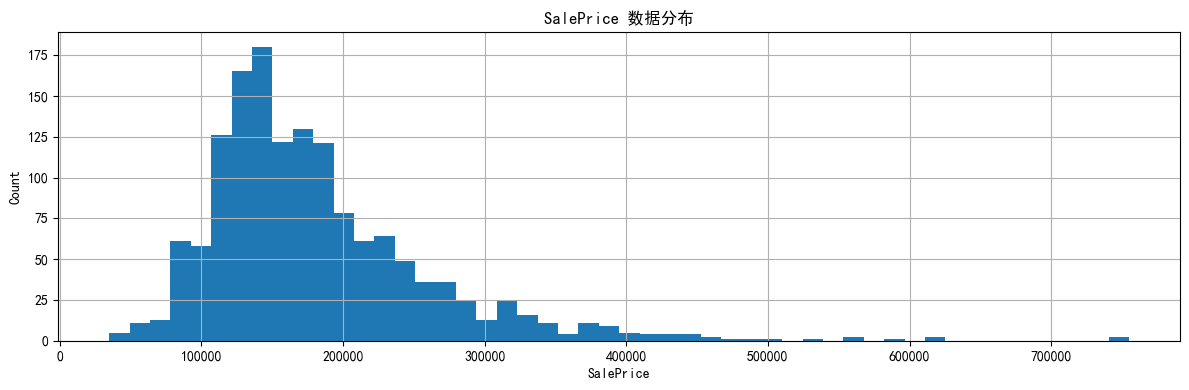

In [5]:
# 训练数据集比测试数据集多一列 "SalePrice"，可以先检查下该列数据的分布情况
import os
import urllib.request
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 1. 下载轻量级中文字体 (文泉驿正黑)
font_url = "https://github.com/StellarCN/scp_zh/raw/master/fonts/SimHei.ttf"
font_path = "/tmp/SimHei.ttf"

if not os.path.exists(font_path):
    print("正在下载中文字体...")
    urllib.request.urlretrieve(font_url, font_path)
    print("下载完成！")

# 2. 加载并应用字体
fm.fontManager.addfont(font_path)
prop = fm.FontProperties(fname=font_path)
plt.rcParams['font.sans-serif'] = [prop.get_name()]
plt.rcParams['axes.unicode_minus'] = False

print(f"✅ 成功配置字体: {prop.get_name()}\n")

# # 设置参数，指定中文字体
# matplotlib.rcParams['font.sans-serif'] = ['SimHei']
# matplotlib.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(12, 4))
train["SalePrice"].hist(bins=50, ax=ax)
ax.set_title("SalePrice 数据分布")
ax.set_xlabel("SalePrice")
ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

从上述 "SalePrice 数据分布" 柱状图中可以看出：
- 数据分布呈右偏态（长尾）分布
- 绝大多数房屋的售价集中在 130,000 到 160,000 之间，且数量约为 175；
- 数据集中接近 80% 的房屋售价在 100,000 到 250,000 这个区间；最低价格在 30,000 左右，最高价格在 800,000 左右；
- 图中右侧长尾延伸至 700,000 以上，说明数据集中存在极少数豪宅；这类样本数量虽少，但价格远高于普通房屋。

基于 "SalePrice 数据分布" 的情况，尝试对 "SalePrice" 进行对数转换，查看数据表现。

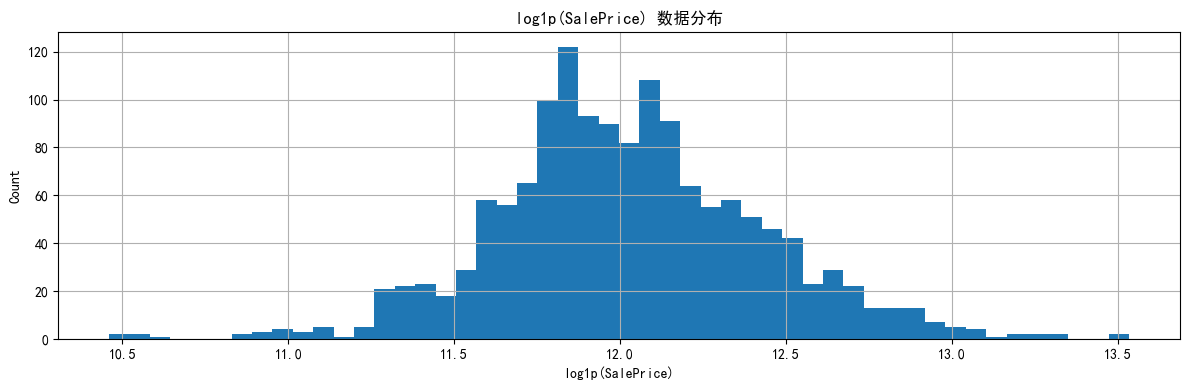

In [6]:
# 对 "SalePrice" 列进行对数转换，并查看数据分布情况
fig_log, ax_log = plt.subplots(figsize=(12, 4))
np.log1p(train["SalePrice"]).hist(bins=50, ax=ax_log)
ax_log.set_title("log1p(SalePrice) 数据分布")
ax_log.set_xlabel("log1p(SalePrice)")
ax_log.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [7]:
high_frequency_range = [11.8, 12.2]
high_frequency_price_range = np.expm1(high_frequency_range)

print(high_frequency_price_range)

[133251.35294553 198788.15114295]


从经对数转换的 "log1p(SalsePrice) 数据分布" 柱状图看出：
- 现在的数据呈现近似中间高、两边低的钟形分布（类似正态分布）；
- 数据的最高频集中点位于 11.8 到 12.2 之间，相当于房屋售价范围 133,000 到 198,000 之间；
- 左右两侧仍有少部分数据（左端 10.5 附近，右端 13.5 附近），但数量上已经非常少了。

**结论：** 建议对训练集中的 ‘SalePrice’ 做对数转换，使目标变量更接近对称分布，从而降低长尾样本对损失函数的支配，帮助模型更好地捕捉特征与价格之间的关系。对于两端的极值点，在后续的探查中仍需留意。

In [8]:
# 发现训练集和测试集中的部分列存在空值，筛选出具有空值的列
train_nan_cols = train.isna().sum()
test_nan_cols = test.isna().sum()

print("======== train_nan_cols =======")
print(train_nan_cols[train_nan_cols > 0])
print("\n")
print("======== test_nan_cols =======")
print(test_nan_cols[test_nan_cols > 0])
print("\n")
print("The number of columns in the training dataset that have missing values:", len(train_nan_cols[train_nan_cols > 0]))
print("The number of columns in the test dataset that have missing values:", len(test_nan_cols[test_nan_cols > 0]))

======== train_nan_cols =======
LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


======== test_nan_cols =======
MSZoning           4
LotFrontage      227
Alley           1352
Utilities          2
Exterior1st        1
Exterior2nd        1
MasVnrType       894
MasVnrArea        15
BsmtQual          44
BsmtCond          45
BsmtExposure      44
BsmtFinType1      42
BsmtFinSF1         1
BsmtFinType2      42
BsmtFinSF2         1
BsmtUnfSF          1
TotalBsmtSF        1
BsmtFullBath       2
BsmtHalfBath       2
KitchenQual        1
Functional         2
FireplaceQu      730
GarageType        76
GarageYrBlt       78
GarageFinish      7

In [9]:
# train_nan_cols 中存在 GarageType、GarageYrBlt、GarageFinish、GarageQual、GarageCond，这几个字段的缺失值均为 81，且字段名的命名方式统一，猜测存在相关性，
# 主要是确认这几个字段的缺失值的行号是否一致

garage_na_cols = ["GarageType", "GarageYrBlt", "GarageFinish", "GarageQual", "GarageCond"]
na_count_per_row = train[garage_na_cols].isna().sum(axis=1)

# 如果这 5 列缺失行完全一致，那么每一行要么 5 列全缺，要么 5 列全不缺，不会出现“缺 1~4 个”的行
print(na_count_per_row.value_counts().sort_index())

0    1379
5      81
Name: count, dtype: int64


从输出结果可知，"GarageType", "GarageYrBlt", "GarageFinish", "GarageQual", "GarageCond" 这五列的缺失值所在行号是一致的，结合 data_description.txt 文件中对这些列的描述，可知是对车库情况的记录，空值均代表没有车库。

In [10]:
# 抽样查看数据
train.sample(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
836,837,30,RM,90.0,8100,Pave,Pave,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Norm,Norm,1Fam,1Story,5,6,1948,1973,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,BrkTil,TA,TA,No,Rec,338,Unf,0,1221,1559,GasA,Gd,Y,SBrkr,1559,0,0,1559,1,0,1,0,2,1,TA,5,Min2,0,NaN,Detchd,1948.0,Unf,2,812,TA,TA,Y,0,116,230,0,0,0,NaN,GdWo,NaN,0,6,2007,COD,Normal,153500
1021,1022,20,RL,64.0,7406,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,1Story,7,5,2006,2006,Gable,CompShg,VinylSd,VinylSd,Stone,84.0,Gd,TA,PConc,Gd,TA,Av,GLQ,684,Unf,0,515,1199,GasA,Ex,Y,SBrkr,1220,0,0,1220,1,0,2,0,2,1,Gd,6,Typ,0,NaN,Attchd,2006.0,RFn,2,632,TA,TA,Y,105,54,0,0,0,0,NaN,NaN,NaN,0,7,2006,New,Partial,194000
569,570,90,RL,NaN,7032,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,Duplex,SFoyer,5,5,1979,1979,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,GLQ,943,Unf,0,0,943,GasA,TA,Y,SBrkr,943,0,0,943,1,0,1,0,2,1,TA,4,Typ,2,TA,Detchd,1979.0,Unf,2,600,TA,TA,Y,42,0,0,0,0,0,NaN,NaN,NaN,0,12,2006,WD,Normal,135960
330,331,90,RL,NaN,10624,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,Duplex,1Story,5,4,1964,1964,Gable,CompShg,HdBoard,HdBoard,BrkFace,84.0,TA,TA,CBlock,TA,TA,No,GLQ,40,Rec,264,1424,1728,GasA,TA,Y,SBrkr,1728,0,0,1728,0,1,2,0,6,2,TA,10,Typ,0,NaN,Detchd,2002.0,Unf,1,352,TA,TA,Y,155,0,0,0,0,0,NaN,NaN,NaN,0,11,2007,WD,Normal,119000
911,912,20,RL,NaN,9286,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Mod,CollgCr,Norm,Norm,1Fam,1Story,5,7,1977,1989,Gable,CompShg,HdBoard,Plywood,NaN,0.0,TA,TA,CBlock,Gd,Gd,Av,ALQ,196,Unf,0,1072,1268,GasA,TA,Y,SBrkr,1268,0,0,1268,0,0,1,1,3,1,Gd,5,Typ,0,NaN,Detchd,1978.0,Unf,1,252,TA,TA,Y,173,0,0,0,0,0,NaN,NaN,NaN,0,10,2009,WD,Normal,143500
1091,1092,160,FV,24.0,2160,Pave,Pave,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,Twnhs,2Story,7,5,1999,2000,Gable,CompShg,MetalSd,MetalSd,BrkFace,212.0,Gd,TA,PConc,Gd,TA,No,BLQ,510,Unf,0,90,600,GasA,Ex,Y,SBrkr,624,628,0,1252,1,0,2,1,2,1,Gd,4,Typ,0,NaN,Detchd,1999.0,Unf,2,462,TA,TA,Y,0,48,0,0,0,0,NaN,NaN,NaN,0,3,2008,WD,Normal,160000
1172,1173,160,FV,35.0,4017,Pave,Pave,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,TwnhsE,2Story,7,5,2006,2007,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,Gd,TA,PConc,Gd,TA,No,Unf,0,Unf,0,625,625,GasA,Ex,Y,SBrkr,625,625,0,1250,0,0,2,1,2,1,Gd,5,Typ,0,NaN,Detchd,2006.0,Fin,2,625,TA,TA,Y,0,54,0,0,0,0,NaN,NaN,NaN,0,3,2008,WD,Normal,171900
1193,1194,120,RM,NaN,4500,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Mitchel,Norm,Norm,TwnhsE,1Story,6,5,1999,1999,Hip,CompShg,VinylSd,VinylSd,BrkFace,425.0,TA,TA,PConc,Ex,TA,No,GLQ,883,Unf,0,341,1224,GasA,Ex,Y,SBrkr,1224,0,0,1224,1,0,2,0,2,1,TA,5,Typ,0,NaN,Attchd,1999.0,Fin,2,402,TA,TA,Y,0,304,0,0,0,0,NaN,NaN,NaN,0,6,2009,WD,Normal,165000
426,427,80,RL,NaN,12800,Pave,NaN,Reg,Low,AllPub,Inside,Mod,SawyerW,Norm,Norm,1Fam,SLvl,7,5,1989,1989,Gable,CompShg,Wd Sdng,Wd Sdng,BrkFace,145.0,Gd,TA,PConc,Gd,TA,Gd,GLQ,1518,Unf,0,0,1518,GasA,Gd,Y,SBrkr,1644,0,0,1644,1,1,2,0,2,1,Gd,5,Typ,1,TA,Attchd,1989.0,Fin,2,569,TA,TA,Y,80,0,0,0,396,0,NaN,NaN,NaN,0,8,2009,WD,Normal,275000
875,876,60,FV,75.0,9000,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,1Fam,2Story,8,5,2007,2007,Gable,CompShg,CemntBd,CmentBd,NaN,0.0,Gd,TA,PConc,Gd,TA,Av,GLQ,6

### 2. Data Processing

通过数据探查发现两个关键事实：
- (1) 训练集比测试集多一列 SalePrice，这是本次建模的目标；
- (2) 训练集有 19 列、测试集有 33 列存在缺失，缺失数量差异较大，不能统一处理。

本章按"先删列 → 再填充 → 最后编码"三步完成特征预处理，每一步都遵循"只在训练集学规则，测试集只套用"的原则。


#### 2.1 Dropping columns

根据各列的说明，以下列需要删除：

- "Id": 递增的数字与销售价格无关，此列应予以删除。
- "MiscFeature": Miscellaneous feature not covered in other categories. 缺失 1406/1460（缺失率约 96%），非缺失样本也仅集中在 Shed 等少数类别，信息量有限，故删除。
- "GarageYrBlt": Year garage was built。空值表示没有车库，该列可以理解为是对是否有车库的情况进行描述，与关联的其余四列存在重复，训练时可以删除该列数据。
- "PoolQC": Pool quality。训练数据集中有 1460 行数据，而该列缺失值却有 1453 行，不具备训练的条件，应予以删除。同时，可以查看下相关的列 "PoolArea"，查看下此列的数据情况。

In [11]:
pool_data = train[["PoolArea", "PoolQC"]].copy()
print("====== GROUP BY ['PoolArea', 'PoolQC'] ======\n", pool_data.value_counts())
print("====== Value of  'PoolArea' ======\n", pool_data["PoolArea"].value_counts())

====== GROUP BY ['PoolArea', 'PoolQC'] ======
 PoolArea  PoolQC
480       Gd        1
512       Ex        1
519       Fa        1
555       Ex        1
576       Gd        1
648       Fa        1
738       Gd        1
Name: count, dtype: int64
====== Value of  'PoolArea' ======
 PoolArea
0      1453
512       1
648       1
576       1
555       1
480       1
519       1
738       1
Name: count, dtype: int64


从结果可以看出，"PoolArea" 列与 "PoolQC" 列的情况相同，"PoolQC" 中的 NA 值对应 "PoolArea" 中的数字 0。

In [12]:
# 查看 "PoolArea" > 0 的数据
poolarea_data = train[train["PoolArea"] > 0]

poolarea_data

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
197,198,75,RL,174.0,25419,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Artery,Norm,1Fam,2Story,8,4,1918,1990,Gable,CompShg,Stucco,Stucco,NaN,0.0,Gd,Gd,PConc,TA,TA,No,GLQ,1036,LwQ,184,140,1360,GasA,Gd,Y,SBrkr,1360,1360,392,3112,1,1,2,0,4,1,Gd,8,Typ,1,Ex,Detchd,1918.0,Unf,2,795,TA,TA,Y,0,16,552,0,0,512,Ex,GdPrv,NaN,0,3,2006,WD,Abnorml,235000
810,811,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,Norm,1Fam,1Story,6,6,1974,1999,Hip,CompShg,HdBoard,HdBoard,BrkFace,99.0,TA,TA,CBlock,TA,TA,No,ALQ,663,LwQ,377,0,1040,GasA,Fa,Y,SBrkr,1309,0,0,1309,1,0,1,1,3,1,Gd,5,Typ,1,Fa,Attchd,1974.0,RFn,2,484,TA,TA,Y,265,0,0,0,0,648,Fa,GdPrv,NaN,0,1,2006,WD,Normal,181000
1170,1171,80,RL,76.0,9880,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,SLvl,6,6,1977,1977,Gable,CompShg,Plywood,Plywood,NaN,0.0,TA,TA,CBlock,TA,TA,Av,ALQ,522,Unf,0,574,1096,GasA,TA,Y,SBrkr,1118,0,0,1118,1,0,1,0,3,1,TA,6,Typ,1,Po,Attchd,1977.0,Fin,1,358,TA,TA,Y,203,0,0,0,0,576,Gd,GdPrv,NaN,0,7,2008,WD,Normal,171000
1182,1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NoRidge,Norm,Norm,1Fam,2Story,10,5,1996,1996,Hip,CompShg,Wd Sdng,ImStucc,NaN,0.0,Gd,TA,PConc,Ex,TA,Av,GLQ,2096,Unf,0,300,2396,GasA,Ex,Y,SBrkr,2411,2065,0,4476,1,0,3,1,4,1,Ex,10,Typ,2,TA,Attchd,1996.0,Fin,3,813,TA,TA,Y,171,78,0,0,0,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000
1298,1299,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644,Unf,0,466,6110,GasA,Ex,Y,SBrkr,4692,950,0,5642,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,2008.0,Fin,2,1418,TA,TA,Y,214,292,0,0,0,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000
1386,1387,60,RL,80.0,16692,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,NWAmes,RRAn,Norm,1Fam,2Story,7,5,1978,1978,Gable,CompShg,Plywood,Plywood,BrkFace,184.0,TA,TA,CBlock,Gd,TA,No,BLQ,790,LwQ,469,133,1392,GasA,TA,Y,SBrkr,1392,1392,0,2784,1,0,3,1,5,1,Gd,12,Typ,2,TA,Attchd,1978.0,RFn,2,564,TA,TA,Y,0,112,0,0,440,519,Fa,MnPrv,TenC,2000,7,2006,WD,Normal,250000
1423,1424,80,RL,NaN,19690,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Edwards,Norm,Norm,1Fam,SLvl,6,7,1966,1966,Flat,Tar&Grv,Plywood,Plywood,NaN,0.0,Gd,Gd,CBlock,Gd,TA,Av,Unf,0,Unf,0,697,697,GasA,TA,Y,SBrkr,1575,626,0,2201,0,0,2,0,4,1,Gd,8,Typ,1,Gd,Attchd,1966.0,Unf,2,432,Gd,Gd,Y,586,236,0,0,0,738,Gd,GdPrv,NaN,0,8,2006,WD,Alloca,274970


观察 "PoolArea" > 0 的 7 条样本，其 PoolArea 分别为 [512, 648, 576, 555, 480, 519, 738]，对应 SalePrice 为 [235000, 181000, 171000, 745000, 160000, 250000, 274970]。这些样本的价格分布在对数变换后分布图的右侧，说明带泳池的房屋售价整体偏高。

因此不应删除 "PoolArea"，而应保留该列，并额外构造一个二元特征 "HasPool"，用于表示房屋是否带泳池。

In [13]:
drop_cols = ["Id", "MiscFeature", "GarageYrBlt", "PoolQC"]

train.drop(columns=drop_cols, inplace=True)
test.drop(columns=drop_cols, inplace=True)

#### 2.2 Handling of missing values

根据前述对数据集的探查，缺失值处理的方式按照以下规则处理：

- "LotFrontage"：Linear feet of street connected to property.
  "BsmtFinSF1":Type 1 finished square feet.
  "BsmtFinSF2":Type 2 finished square feet.
  "BsmtUnfSF":Unfinished square feet of basement area.
  "TotalBsmtSF":Total square feet of basement area.
  "BsmtFullBath":Basement full bathrooms.
  "BsmtHalfBath":Basement half bathrooms.
  "GarageCars"：Size of garage in car capacity.
  "GarageArea":Size of garage in square feet.

      根据字段的描述可知，该列的 NaN 可能是由于数据缺失导致的，可以使用中位数进行填充。

- "Alley"：Type of alley access.
  "MasVnrType"：Masonry veneer type.
  "BsmtQual"：Height of the basement.
  "BsmtCond"：General condition of the basement.
  "BsmtExposure"：Walkout or garden level basement walls.
  "BsmtFinType1"：Quality of basement finished area.
  "BsmtFinType2"：Quality of second finished area (if present).
  "FireplaceQu"：Fireplace quality.
  "GarageType":Garage location.
  "GarageFinish":Interior finish of the garage.
  "GarageQual":Garage quality.
  "GarageCond":Garage condition.
  "Fence"：Fence quality.

      根据 data_description.txt 文件的内容，这里 NA 可以用 "Missing" 来替换，
      同样表示 No alley access、None、No Basement、No Fireplace、No Garage、No Fence。

- "MasVnrArea"：Masonry veneer area in square feet.

      经 1.2 后的探查发现，"MasVnrArea" 缺失时 "MasVnrType" 也同时缺失，而 "MasVnrType" 的缺失表示该房屋没有砌体贴面（None），因此 "MasVnrArea" 的缺失可以直接填充为 0。

- "Electrical"：Electrical system.
  "MSZoning":The general zoning classification.
  ""Utilities"":Type of utilities available.
  "Exterior1st":Exterior covering on house.
  "Exterior2nd":Exterior covering on house (if more than one material).
  "KitchenQual":Kitchen quality.
  "Functional":Home functionality rating.
  "SaleType":Type of sale.

      这些列的缺失值没有明确的业务含义，采用众数填充是一种合理的简化处理；若后续模型表现受限，可进一步结合具体字段做分组填充。


In [14]:
# 先对 "MasVnrArea" 列的数据进行进一步探查，确定该列缺失值的处理方式。
pd.crosstab(train["MasVnrArea"].isna(), train["MasVnrType"].isna())

MasVnrType,False,True
MasVnrArea,,
False,588,864
True,0,8


从上面输出的内容显示，"MasVnrArea" 字段空值时，"MasVnrType" 字段也是空值，且 "MasVnrType" 中的空值表示 None，即可以认定对应的 "MasVnrArea" 的空值可以填充为数字 0。

In [15]:
median_impute_cols = [
    "LotFrontage", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath", "GarageCars", "GarageArea"
]
missing_impute_cols = [
    "Alley", "MasVnrType","BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu", "GarageType",
    "GarageFinish", "GarageQual", "GarageCond", "Fence"
]
zero_impute_cols = [
    "MasVnrArea"
]
mode_impute_cols = [
    "Electrical", "MSZoning", "Utilities", "Exterior1st",
    "Exterior2nd", "KitchenQual", "Functional", "SaleType"
]

# 创建缺失值填充函数
def na_value_fill(train, test, median_impute_cols, missing_impute_cols, zero_impute_cols, mode_impute_cols):

    # 填充中位数
    for col in median_impute_cols:
        median_value = train[col].median()
        train[col] = train[col].fillna(median_value)
        test[col] = test[col].fillna(median_value)

    # 填充 "Missing"
    for col in missing_impute_cols:
        train[col] = train[col].fillna("Missing")
        test[col] = test[col].fillna("Missing")

    # 填充数字 0
    for col in zero_impute_cols:
        train[col] = train[col].fillna(0)
        test[col] = test[col].fillna(0)

    # 填充众数
    for col in mode_impute_cols:
        mode_value = train[col].mode()[0]
        train[col] = train[col].fillna(mode_value)
        test[col] = test[col].fillna(mode_value)

    return train, test

In [16]:
# 调用 na_value_fill 函数处理缺失值
train_aft_impute, test_aft_impute = na_value_fill(train, test, median_impute_cols, missing_impute_cols, zero_impute_cols, mode_impute_cols)

In [17]:
train_still_na = train_aft_impute.isna().sum()
test_still_na = test_aft_impute.isna().sum()


print("========== still have missing values ==========：\n", train_still_na[train_still_na > 0])
print("========== still have missing values ==========：\n", test_still_na[train_still_na > 0])

========== still have missing values ==========：
 Series([], dtype: int64)
========== still have missing values ==========：
 Series([], dtype: int64)


#### 2.3 Feature Engineering

结合 1.2 对 "GarageType"、"GarageYrBlt"、"GarageFinish"、"GarageQual"、"GarageCond" 列的探查，以及 2.1 对 "PoolArea" 列的处理思路，再次借助 data_description.txt 文件查看各列，有以下几个发现：
- 有地下室总面积 "TotalBsmtSF"，以及其组成部分 "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF"，但是对于地上部分的描述仅仅中有 "1stFlrSF", "2ndFlrSF"，在买卖房屋的业务中，整体总面积对房屋售价存在一定的影响，可以增加房屋总面积 "TotalSF" = "TotalBsmtSF" + "1stFlrSF" + "2ndFlrSF"；对于门廊的描述，可以增加门廊总面积 "TotalPorchSF" = "WoodDeckSF" + "OpenPorchSF" + "EnclosedPorch" + "3SsnPorch" + "ScreenPorch"。
- "TotRmsAbvGrd" 列的描述是 Total rooms above grade (does not include bathrooms)，并没有包含卫生间，可以增加总卫浴 "TotalBath" = "FullBath" + 0.5 * "HalfBath" + "BsmtFullBath" + 0.5 * "BsmtHalfBath"，其中带有 "half" 的列系数为 0.5。
- 对于房屋实际的存在时间，即房龄，并没有相应的列进行描述，可以增加房龄 "HouseAge" = "YrSold" - "YearBuilt"，翻新间隔 "RemodAge" = "YrSold" - "YearRemodAdd"；同时 "YearRemodAdd" 列的描述是 Remodel date (same as construction date if no remodeling or additions)，可以增加 "IsRemodel"，判断是否为改造、翻新的房屋。
- 对房屋各类设施的有无做判断，增加 "HasGarage"，"HasPool"，"HasBsmt"，"HasFireplace"，"Has2ndFloor"。

In [18]:
# 创建 add_features 函数
def add_features(df):
    df = df.copy()

    # TotalSF
    df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
    # TotalPorchSF
    df["TotalPorchSF"] = df["WoodDeckSF"] + df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"]
    # TotalBath
    df["TotalBath"] = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]

    # HouseAge
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
    # RemodAge
    df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
    # IsRemodel
    df["IsRemodel"] = (df["YearBuilt"] != df["YearRemodAdd"]).astype(int)

    # HasGarage
    df["HasGarage"] = (df["GarageArea"] > 0).astype(int)
    # HasPool
    df["HasPool"] = (df["PoolArea"] > 0).astype(int)
    # HasBsmt
    df["HasBsmt"] = (df["TotalBsmtSF"] > 0).astype(int)
    # HasFireplace
    df["HasFireplace"] = (df["Fireplaces"] > 0).astype(int)
    # Has2ndFloor
    df["Has2ndFloor"] = (df["2ndFlrSF"] > 0).astype(int)

    return df


In [19]:
# 调用 add_features
train_add_features = add_features(train_aft_impute)

#### 2.4 Correlation analysis

In [20]:
# 筛选出所有的数值类型
num_feature_cols = train_add_features.select_dtypes(include=[np.number]).columns.drop("SalePrice")

# 计算相关系数
corr_with_price = train_add_features[num_feature_cols].corrwith(train_add_features["SalePrice"])

# 按照绝对值降序排序
corr_with_price = corr_with_price.sort_values(key=abs, ascending=False)

print("======== 与 SalePrice 相关性 ========")
print(corr_with_price)

======== 与 SalePrice 相关性 ========
OverallQual      0.790982
TotalSF          0.782260
GrLivArea        0.708624
GarageCars       0.640409
TotalBath        0.631731
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
HouseAge        -0.523350
YearBuilt        0.522897
RemodAge        -0.509079
YearRemodAdd     0.507101
MasVnrArea       0.472614
HasFireplace     0.471908
Fireplaces       0.466929
TotalPorchSF     0.390993
BsmtFinSF1       0.386420
LotFrontage      0.334771
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
HasGarage        0.236832
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
HasBsmt          0.152829
Has2ndFloor      0.137656
KitchenAbvGr    -0.135907
EnclosedPorch   -0.128578
ScreenPorch      0.111447
HasPool          0.093708
PoolArea         0.092404
MSSubClass      -0.084284
Over

特征相关性分析与结论：
- 核心特征与特征工程的成功："OverallQual"（Overall material and finish quality）以 0.79 的高相关性位居榜首，是决定房价的最核心要素。值得注意的是，新增加的 "TotalSF"（房屋总面积，0.78） 和 "TotalBath"（总卫浴，0.63） 表现极其出色，远超它们对应的原始子特征（如 "GrLivArea"、"TotalBsmtSF" 等）。这说明通过融合分散的信息，模型获得了更强大的信号。
- 符合业务逻辑的负相关："HouseAge"（房龄，-0.52）和 "RemodAge"（翻新间隔，-0.51）呈现明显的负相关，说明房龄越大、装修越久，价值越低，完全符合常理。"OverallCond"（Overall condition rating）呈极微弱的负相关，推测是由于部分老旧房屋经过翻新后，由于建造年份较早，整体评分仍不高，导致其并未体现出应有的增值。
- 冗余与处理方案：列表中存在高度共线性的特征组（如 "TotalSF" 与 "GrLivArea"/"TotalBsmtSF"；"HouseAge" 与 "YearBuilt"）。由于后续使用的 XGBoost 属于树模型，对多重共线性并不敏感，模型能够自动捕捉最有效的分裂点。因此，本次保留所有特征不做删除，让树模型自行选择。
- 尾部低相关特征：虽然 "MiscVal"、"LowQualFinSF" 等特征相关性趋近于 0，但考虑到它们可能包含极少数特殊房屋（如带特殊设施的豪宅）的信息，且不影响模型的整体运行效率，一并保留。

#### 2.5 Identification of outliers

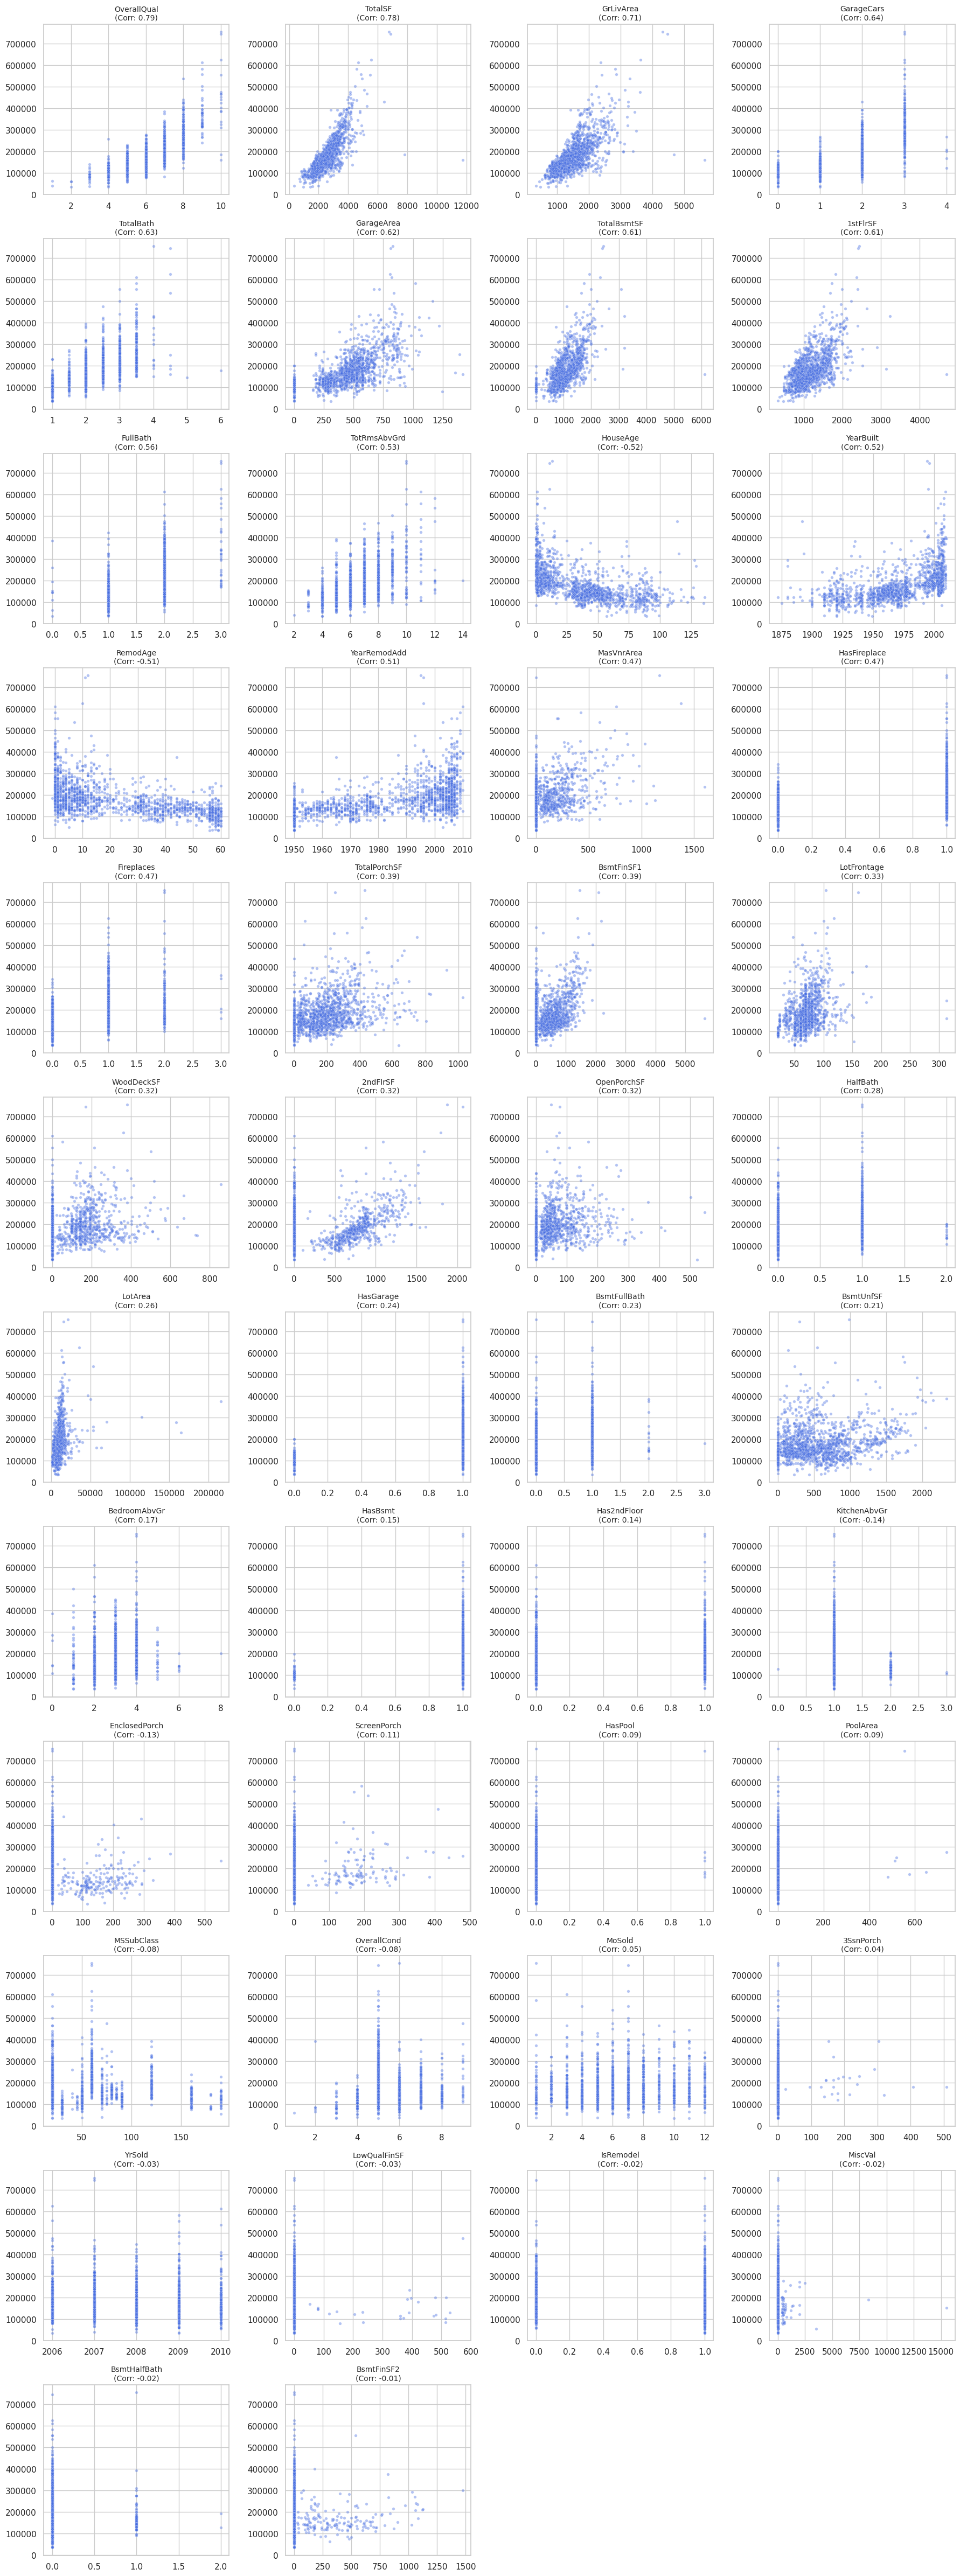

In [22]:
# 对数值类型的列进行散点图的绘制
import seaborn as sns
import math

# 设置画图风格
sns.set_theme(style="whitegrid")

corr_cols = corr_with_price.index

# 计算画布尺寸
n_feature_cols = len(corr_cols)
n_cols = 4
n_rows = math.ceil(n_feature_cols / n_cols)

# 设置画布大小
fig_ot, axes_ot = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes_ot = axes_ot.flatten()

# 循环绘制
for i, col in enumerate(corr_cols):
    sns.scatterplot(
        x=train_add_features[col],
        y=train_add_features["SalePrice"],
        ax=axes_ot[i],
        alpha=0.4,
        s=15,
        color="royalblue"
    )

    corr_val = corr_with_price[col]
    axes_ot[i].set_title(f"{col}\n(Corr: {corr_val:.2f})", fontsize=10)
    axes_ot[i].set_xlabel("")
    axes_ot[i].set_ylabel("")

# 隐藏多余的空白子图
for j in range(len(corr_cols), len(axes_ot)):
    axes_ot[j].set_visible(False)

plt.tight_layout()
plt.show()

观察上述散点图，发现以下几处异常点：
- OverallQual：
    - 评分 10 的位置，存在两个点的售价极低，在 200,000 以下，OverallQual 与 SalePrice 的相关性系数为 0.79，正相关，正常来讲，OverallQual 的值越大，SalePrice 的值也越大，需要进一步查看这部分异常的数据。
    - 评分 4 的位置，有一个点的售价远高于其主体部分，售价在 250,000 左右。
- TotalSF：房屋总面积大于 7,800 左右有两个点的售价偏低，低于 200,000。
- GrLivArea：在面积大于 4,600 左右时，有两个异常点，售价极低，低于 200,000。
- GarageCars：corr 系数为 0.64，属于正相关，但在数值 4 时，售价不增反降。
- TotalBath：需要查看下总卫浴数为 5，6 的数据情况。
- GarageArea：在车库面积大于等于 1250 时，该部分的房屋售价较低。
- TotalBsmtSF：右下角，地下室总面积大于 6,000 的部分有一个点，售价极低。
- 1stFlrSF：右下角，一楼面积大于 3,000 的部分有两个点，售价较低，低于 200,000。
- TotRmsAbvGrd：地上部分的总房间数(不含卫生间)的数值为 14 时，售价偏低。
- HouseAge 与 YearBuilt：在 HouseAge 值 120 附近（100 - 125 区间）和 YearBuilt 值 1890 附近（1875 - 1900 区间）存在售价偏高的两个点，售价大于 300,000。
- BsmtFinSF1：1 类完工面积大于 5,000 的数据。

In [23]:
# OverallQual：评分 10 的位置，存在两个点的售价极低，在 200,000 以下；评分 4 的位置，有一个点的售价远高于其主体部分，售价在 250,000 左右
condition_1 = ((train_add_features["OverallQual"] == 10) & (train_add_features["SalePrice"] < 200000))
condition_2 = ((train_add_features["OverallQual"] == 4) & (train_add_features["SalePrice"] > 200000))

overallqual_data = train_add_features[(condition_1 | condition_2)]

overallqual_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,IsRemodel,HasGarage,HasPool,HasBsmt,HasFireplace,Has2ndFloor
457,20,RL,69.0,53227,Pave,Missing,IR1,Low,AllPub,CulDSac,Mod,ClearCr,Norm,Norm,1Fam,1Story,4,6,1954,1994,Flat,Tar&Grv,Plywood,Plywood,Missing,0.0,TA,TA,CBlock,Gd,TA,Gd,BLQ,1116,Unf,0,248,1364,GasA,Ex,Y,SBrkr,1663,0,0,1663,1,0,1,0,2,1,Gd,6,Min1,2,Gd,Attchd,Fin,2,529,TA,TA,Y,224,137,0,0,0,0,Missing,0,3,2008,WD,Normal,256000,3027,361,2.0,54,14,1,1,0,1,1,0
523,60,RL,130.0,40094,Pave,Missing,IR1,Bnk,AllPub,Inside,Gtl,Edwards,PosN,PosN,1Fam,2Story,10,5,2007,2008,Hip,CompShg,CemntBd,CmentBd,Stone,762.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,2260,Unf,0,878,3138,GasA,Ex,Y,SBrkr,3138,1538,0,4676,1,0,3,1,3,1,Ex,11,Typ,1,Gd,BuiltIn,Fin,3,884,TA,TA,Y,208,406,0,0,0,0,Missing,0,10,2007,New,Partial,184750,7814,614,4.5,0,-1,1,1,0,1,1,1
1298,60,RL,313.0,63887,Pave,Missing,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644,Unf,0,466,6110,GasA,Ex,Y,SBrkr,4692,950,0,5642,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,Fin,2,1418,TA,TA,Y,214,292,0,0,0,480,Missing,0,1,2008,New,Partial,160000,11752,506,4.5,0,0,0,1,1,1,1,1


In [24]:
# 缩小比较范围，找出产生异常的原因
adjust_cols = [
    "OverallQual", "SalePrice", "YearBuilt", "YearRemodAdd",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
    "BsmtFinSF1", "BsmtFinType2", "BsmtFinSF2", "BsmtUnfSF",
    "YrSold", "TotalBsmtSF", "TotalSF", "HouseAge", "RemodAge"
]
overallqual_data[adjust_cols]

,OverallQual,SalePrice,YearBuilt,YearRemodAdd,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,YrSold,TotalBsmtSF,TotalSF,HouseAge,RemodAge
457,4,256000,1954,1994,Gd,TA,Gd,BLQ,1116,Unf,0,248,2008,1364,3027,54,14
523,10,184750,2007,2008,Ex,TA,Gd,GLQ,2260,Unf,0,878,2007,3138,7814,0,-1
1298,10,160000,2008,2008,Ex,TA,Gd,GLQ,5644,Unf,0,466,2008,6110,11752,0,0


这三条数据的 "BsmtFinType2" 的值均为 "Unf"，表示 "未完工"，对于房屋销售业务，存在未完工的设施时，房屋售价会比较低；"OverallQual" 值为 10 的两条数据，"YearBuilt" 与 "YrSold" 的年份相同，属于新房，并且 "TotalSF" 值为 7,814 和 1,1752，借助散点图可以得知 "TotalSF" 与 "SalePrice" 正相关，房屋总面积越大，房屋售价也就越高，并且该数值下的房屋一般来说属于 "豪宅" 范畴，理应房屋售价高于普通房屋，而唯一的不足之处是存在未完工的设施，大大降低了房屋售价，对于此类数据，应该予以删除；"OverallQual" 值为 4 时，"YearBuilt" 值为 1954，属于旧房，此类房屋售价一般不高，但是该房屋的总面积为 3027，在 "TotalSF" 的散点图中，房屋总面积为 3000 左右的房屋售价范围为 90,000 到 270,000 之间，该房屋的售价为 256,000 属于合理范围，所以该条数据无异常情况，不用排除。

In [25]:
# TotalSF：房屋总面积大于 7,800 左右有两个点的售价偏低，低于 200,000。
totalsf_data = train_add_features[train_add_features["TotalSF"] > 7800]

totalsf_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,IsRemodel,HasGarage,HasPool,HasBsmt,HasFireplace,Has2ndFloor
523,60,RL,130.0,40094,Pave,Missing,IR1,Bnk,AllPub,Inside,Gtl,Edwards,PosN,PosN,1Fam,2Story,10,5,2007,2008,Hip,CompShg,CemntBd,CmentBd,Stone,762.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,2260,Unf,0,878,3138,GasA,Ex,Y,SBrkr,3138,1538,0,4676,1,0,3,1,3,1,Ex,11,Typ,1,Gd,BuiltIn,Fin,3,884,TA,TA,Y,208,406,0,0,0,0,Missing,0,10,2007,New,Partial,184750,7814,614,4.5,0,-1,1,1,0,1,1,1
1298,60,RL,313.0,63887,Pave,Missing,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644,Unf,0,466,6110,GasA,Ex,Y,SBrkr,4692,950,0,5642,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,Fin,2,1418,TA,TA,Y,214,292,0,0,0,480,Missing,0,1,2008,New,Partial,160000,11752,506,4.5,0,0,0,1,1,1,1,1


筛选出 "TotalSF" 列大于 7800 的数据，发现这部分数据与 "OverallQual" 中需要剔除的异常值相同。查看 "GrLivArea" 列的异常点，发现面积大于 4600，且房屋售价低于 200,000 的条件，上述这两条数据也符合，所以这两条数据是必须要删除的。

In [26]:
# GarageCars：corr 系数为 0.64，属于正相关，但在数值 4 时，售价不增反降。
garagecars_data = train_add_features[train_add_features["GarageCars"] == 4]

garagecars_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,IsRemodel,HasGarage,HasPool,HasBsmt,HasFireplace,Has2ndFloor
420,90,RM,78.0,7060,Pave,Missing,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,Duplex,SFoyer,7,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,BrkFace,200.0,TA,Gd,PConc,Gd,Gd,Gd,GLQ,1309,Unf,0,35,1344,GasA,Ex,Y,SBrkr,1344,0,0,1344,2,0,2,0,2,2,TA,8,Typ,0,Missing,Attchd,Fin,4,784,TA,TA,Y,0,0,0,0,0,0,Missing,0,11,2008,WD,Alloca,206300,2688,0,4.0,11,10,1,1,0,1,0,0
747,70,RM,65.0,11700,Pave,Pave,IR1,Lvl,AllPub,Corner,Gtl,OldTown,Norm,Norm,1Fam,2Story,7,7,1880,2003,Mansard,CompShg,Stucco,Stucco,Missing,0.0,Gd,TA,Stone,TA,Fa,No,Unf,0,Unf,0,1240,1240,GasW,TA,N,SBrkr,1320,1320,0,2640,0,0,1,1,4,1,Gd,8,Typ,1,Gd,Detchd,Unf,4,864,TA,TA,N,181,0,386,0,0,0,Missing,0,5,2009,WD,Normal,265979,3880,567,1.5,129,6,1,1,0,1,1,1
1190,190,RL,69.0,32463,Pave,Missing,Reg,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,2fmCon,1Story,4,4,1961,1975,Gable,CompShg,MetalSd,MetalSd,Stone,149.0,TA,Gd,CBlock,TA,TA,Av,BLQ,1159,Unf,0,90,1249,GasA,Ex,Y,SBrkr,1622,0,0,1622,1,0,1,0,3,1,TA,7,Typ,1,TA,2Types,Fin,4,1356,TA,TA,Y,439,0,0,0,0,0,Missing,0,3,2007,WD,Normal,168000,2871,439,2.0,46,32,1,1,0,1,1,0
1340,20,RL,70.0,8294,Pave,Missing,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,4,5,1971,1971,Gable,CompShg,MetalSd,MetalSd,Missing,0.0,TA,TA,CBlock,TA,TA,No,Unf,0,Unf,0,858,858,GasA,TA,Y,SBrkr,872,0,0,872,0,0,1,0,3,1,TA,5,Typ,0,Missing,Detchd,Unf,4,480,TA,TA,Y,0,0,0,0,0,0,GdWo,0,6,2007,WD,Normal,123000,1730,0,1.0,36,36,0,1,0,1,0,0
1350,90,RL,91.0,11643,Pave,Missing,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Artery,Norm,Duplex,2Story,5,5,1969,1969,Gable,CompShg,MetalSd,MetalSd,BrkFace,368.0,TA,TA,CBlock,TA,TA,No,LwQ,500,Unf,0,748,1248,GasA,TA,Y,SBrkr,1338,1296,0,2634,1,1,2,2,6,2,TA,12,Typ,0,Missing,Detchd,Unf,4,968,TA,TA,Y,0,0,0,0,0,0,Missing,0,8,2009,WD,Normal,200000,3882,0,4.5,40,40,0,1,0,1,0,1


从 garagecars_data 的数据中，这几套房屋的 "OverallQual" 数值在 4 到 7 之间，在散点图中对应的售价范围是 40,000 到 400,000 之间；"TotalSF" 数值在 1700 到 3900 之间，对应散点图中的售价范围是 80,000 到 280,000 之间；同时这几套房屋的地下室部分均存在未完工的状态，"BsmtUnfSF" 大于 0，会降低房屋的售价；这些房屋的房龄，只有一套为 11，其余四套的房龄均很高，属于老房，房屋价格自然不会很高。 综上，"GarageCars" 为 4 时的数据正常，不需要排除。

In [27]:
# TotalBath：需要查看下总卫浴数为 5，6 的数据情况。
totalbath_data =train_add_features[train_add_features["TotalBath"] >= 5]

totalbath_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,IsRemodel,HasGarage,HasPool,HasBsmt,HasFireplace,Has2ndFloor
738,90,RL,60.0,10800,Pave,Missing,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Norm,Norm,Duplex,1Story,5,5,1987,1988,Gable,CompShg,Plywood,Plywood,Missing,0.0,TA,TA,CBlock,Gd,Gd,Gd,GLQ,1200,Unf,0,0,1200,GasA,TA,Y,SBrkr,1200,0,0,1200,3,0,3,0,3,1,TA,5,Typ,0,Missing,Missing,Missing,0,0,Missing,Missing,Y,120,0,0,0,0,0,Missing,0,3,2009,WD,Alloca,179000,2400,120,6.0,22,21,1,0,0,1,0,0
921,90,RL,67.0,8777,Pave,Missing,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Feedr,Norm,Duplex,1.5Fin,5,7,1900,2003,Gable,CompShg,MetalSd,MetalSd,Missing,0.0,TA,TA,CBlock,TA,TA,No,ALQ,1084,Unf,0,188,1272,GasA,Gd,Y,SBrkr,1272,928,0,2200,2,0,2,2,4,2,TA,9,Typ,0,Missing,Missing,Missing,0,0,Missing,Missing,N,0,70,0,0,0,0,GdPrv,0,9,2008,WD,Normal,145900,3472,70,5.0,108,5,1,0,0,1,0,1


totalbath_data 中这两套房屋 "OverallQual" 的评分均为 5，"TotalSF" 分别为 2400、3472，并且房龄也比较高，一套房龄是 22，另一套房龄是 108，所以排除异常的可能性。

In [28]:
# GarageArea：在车库面积大于等于 1250 时，该部分的房屋售价较低。
garagearea_data = train_add_features[train_add_features["GarageArea"] >= 1250]

garagecars_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,IsRemodel,HasGarage,HasPool,HasBsmt,HasFireplace,Has2ndFloor
420,90,RM,78.0,7060,Pave,Missing,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,Duplex,SFoyer,7,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,BrkFace,200.0,TA,Gd,PConc,Gd,Gd,Gd,GLQ,1309,Unf,0,35,1344,GasA,Ex,Y,SBrkr,1344,0,0,1344,2,0,2,0,2,2,TA,8,Typ,0,Missing,Attchd,Fin,4,784,TA,TA,Y,0,0,0,0,0,0,Missing,0,11,2008,WD,Alloca,206300,2688,0,4.0,11,10,1,1,0,1,0,0
747,70,RM,65.0,11700,Pave,Pave,IR1,Lvl,AllPub,Corner,Gtl,OldTown,Norm,Norm,1Fam,2Story,7,7,1880,2003,Mansard,CompShg,Stucco,Stucco,Missing,0.0,Gd,TA,Stone,TA,Fa,No,Unf,0,Unf,0,1240,1240,GasW,TA,N,SBrkr,1320,1320,0,2640,0,0,1,1,4,1,Gd,8,Typ,1,Gd,Detchd,Unf,4,864,TA,TA,N,181,0,386,0,0,0,Missing,0,5,2009,WD,Normal,265979,3880,567,1.5,129,6,1,1,0,1,1,1
1190,190,RL,69.0,32463,Pave,Missing,Reg,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,2fmCon,1Story,4,4,1961,1975,Gable,CompShg,MetalSd,MetalSd,Stone,149.0,TA,Gd,CBlock,TA,TA,Av,BLQ,1159,Unf,0,90,1249,GasA,Ex,Y,SBrkr,1622,0,0,1622,1,0,1,0,3,1,TA,7,Typ,1,TA,2Types,Fin,4,1356,TA,TA,Y,439,0,0,0,0,0,Missing,0,3,2007,WD,Normal,168000,2871,439,2.0,46,32,1,1,0,1,1,0
1340,20,RL,70.0,8294,Pave,Missing,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,4,5,1971,1971,Gable,CompShg,MetalSd,MetalSd,Missing,0.0,TA,TA,CBlock,TA,TA,No,Unf,0,Unf,0,858,858,GasA,TA,Y,SBrkr,872,0,0,872,0,0,1,0,3,1,TA,5,Typ,0,Missing,Detchd,Unf,4,480,TA,TA,Y,0,0,0,0,0,0,GdWo,0,6,2007,WD,Normal,123000,1730,0,1.0,36,36,0,1,0,1,0,0
1350,90,RL,91.0,11643,Pave,Missing,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Artery,Norm,Duplex,2Story,5,5,1969,1969,Gable,CompShg,MetalSd,MetalSd,BrkFace,368.0,TA,TA,CBlock,TA,TA,No,LwQ,500,Unf,0,748,1248,GasA,TA,Y,SBrkr,1338,1296,0,2634,1,1,2,2,6,2,TA,12,Typ,0,Missing,Detchd,Unf,4,968,TA,TA,Y,0,0,0,0,0,0,Missing,0,8,2009,WD,Normal,200000,3882,0,4.5,40,40,0,1,0,1,0,1


garagearea_data 中筛选出的 5 条数据均已经在 garagecars_data 中出现，已经被认定为正常数据。

In [29]:
# TotalBsmtSF：右下角，地下室总面积大于 6,000 的部分有一个点，售价极低。
totalbsmtsf_data = train_add_features[train_add_features["TotalBsmtSF"] > 6000]

totalbsmtsf_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,IsRemodel,HasGarage,HasPool,HasBsmt,HasFireplace,Has2ndFloor
1298,60,RL,313.0,63887,Pave,Missing,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644,Unf,0,466,6110,GasA,Ex,Y,SBrkr,4692,950,0,5642,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,Fin,2,1418,TA,TA,Y,214,292,0,0,0,480,Missing,0,1,2008,New,Partial,160000,11752,506,4.5,0,0,0,1,1,1,1,1


totalbsmtsf_data 中的这条数据，在 overallqual_data 中已经被认定为异常数据，需要删除。

In [30]:
# 1stFlrSF：右下角，一楼面积大于 3,000 的部分有两个点，售价较低，低于 200,000。
stflrsf_data = train_add_features[((train_add_features["1stFlrSF"] > 3000) & (train_add_features["SalePrice"] < 200000))]

stflrsf_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,IsRemodel,HasGarage,HasPool,HasBsmt,HasFireplace,Has2ndFloor
523,60,RL,130.0,40094,Pave,Missing,IR1,Bnk,AllPub,Inside,Gtl,Edwards,PosN,PosN,1Fam,2Story,10,5,2007,2008,Hip,CompShg,CemntBd,CmentBd,Stone,762.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,2260,Unf,0,878,3138,GasA,Ex,Y,SBrkr,3138,1538,0,4676,1,0,3,1,3,1,Ex,11,Typ,1,Gd,BuiltIn,Fin,3,884,TA,TA,Y,208,406,0,0,0,0,Missing,0,10,2007,New,Partial,184750,7814,614,4.5,0,-1,1,1,0,1,1,1
1298,60,RL,313.0,63887,Pave,Missing,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644,Unf,0,466,6110,GasA,Ex,Y,SBrkr,4692,950,0,5642,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,Fin,2,1418,TA,TA,Y,214,292,0,0,0,480,Missing,0,1,2008,New,Partial,160000,11752,506,4.5,0,0,0,1,1,1,1,1


stflrsf_data 中的这两条数据，在 overallqual_data 中均已经被认定为异常数据，需要删除。

In [31]:
# TotRmsAbvGrd：地上部分的总房间数(不含卫生间)的数值为 14 时，售价偏低。
totrmsabvgrd_data = train_add_features[train_add_features["TotRmsAbvGrd"] == 14]

totrmsabvgrd_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,IsRemodel,HasGarage,HasPool,HasBsmt,HasFireplace,Has2ndFloor
635,190,RH,60.0,10896,Pave,Pave,Reg,Bnk,AllPub,Inside,Gtl,SWISU,Feedr,Norm,2fmCon,2.5Fin,6,7,1914,1995,Hip,CompShg,VinylSd,VinylSd,Missing,0.0,Fa,TA,CBlock,TA,Fa,No,LwQ,256,Unf,0,1184,1440,GasA,Ex,Y,FuseA,1440,1440,515,3395,0,0,2,0,8,2,Fa,14,Typ,0,Missing,Missing,Missing,0,0,Missing,Missing,N,0,110,0,0,0,0,Missing,0,3,2007,WD,Abnorml,200000,4320,110,2.0,93,12,1,0,0,1,0,1


totrmsabvgrd_data 中，影响该房屋价格偏低的因素主要有房龄（HouseAge=93）比较高，存在未完成的设施（BsmtUnfSF=1184，TotalBsmtSF=1440，地下室大部分面积处于未完工的状态），由此可以判断该数据无异常。

In [32]:
# HouseAge 与 YearBuilt：在 HouseAge 值 120 附近（100 - 125 区间）和 YearBuilt 值 1890 附近（1875 - 1900 区间）存在售价偏高的两个点，售价大于 300,000。
houseage_range = ((train_add_features["HouseAge"] > 100) & (train_add_features["HouseAge"] < 125))
saleprice_lt_30w = (train_add_features["SalePrice"] > 300000)

houseage_data = train_add_features[(houseage_range & saleprice_lt_30w)]

houseage_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,IsRemodel,HasGarage,HasPool,HasBsmt,HasFireplace,Has2ndFloor
185,75,RM,90.0,22950,Pave,Missing,IR2,Lvl,AllPub,Inside,Gtl,OldTown,Artery,Norm,1Fam,2.5Fin,10,9,1892,1993,Gable,WdShngl,Wd Sdng,Wd Sdng,Missing,0.0,Gd,Gd,BrkTil,TA,TA,Mn,Unf,0,Unf,0,1107,1107,GasA,Ex,Y,SBrkr,1518,1518,572,3608,0,0,2,1,4,1,Ex,12,Typ,2,TA,Detchd,Unf,3,840,Ex,TA,Y,0,260,0,0,410,0,GdPrv,0,6,2006,WD,Normal,475000,4143,670,2.5,114,13,1,1,0,1,1,1
583,75,RM,75.0,13500,Pave,Missing,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Artery,PosA,1Fam,2.5Unf,10,9,1893,2000,Gable,CompShg,Wd Sdng,Wd Sdng,Missing,0.0,Ex,Ex,BrkTil,TA,TA,No,Unf,0,Unf,0,1237,1237,GasA,Gd,Y,SBrkr,1521,1254,0,2775,0,0,3,1,3,1,Gd,9,Typ,1,Gd,Detchd,Unf,2,880,Gd,TA,Y,105,502,0,0,0,0,Missing,0,7,2008,WD,Normal,325000,4012,607,3.5,115,8,1,1,0,1,1,1


In [33]:
yearbuilt_range = ((train_add_features["YearBuilt"] > 1875) & (train_add_features["YearBuilt"] < 1900))

yearbuilt_data = train_add_features[(yearbuilt_range & saleprice_lt_30w)]

yearbuilt_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,IsRemodel,HasGarage,HasPool,HasBsmt,HasFireplace,Has2ndFloor
185,75,RM,90.0,22950,Pave,Missing,IR2,Lvl,AllPub,Inside,Gtl,OldTown,Artery,Norm,1Fam,2.5Fin,10,9,1892,1993,Gable,WdShngl,Wd Sdng,Wd Sdng,Missing,0.0,Gd,Gd,BrkTil,TA,TA,Mn,Unf,0,Unf,0,1107,1107,GasA,Ex,Y,SBrkr,1518,1518,572,3608,0,0,2,1,4,1,Ex,12,Typ,2,TA,Detchd,Unf,3,840,Ex,TA,Y,0,260,0,0,410,0,GdPrv,0,6,2006,WD,Normal,475000,4143,670,2.5,114,13,1,1,0,1,1,1
583,75,RM,75.0,13500,Pave,Missing,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Artery,PosA,1Fam,2.5Unf,10,9,1893,2000,Gable,CompShg,Wd Sdng,Wd Sdng,Missing,0.0,Ex,Ex,BrkTil,TA,TA,No,Unf,0,Unf,0,1237,1237,GasA,Gd,Y,SBrkr,1521,1254,0,2775,0,0,3,1,3,1,Gd,9,Typ,1,Gd,Detchd,Unf,2,880,Gd,TA,Y,105,502,0,0,0,0,Missing,0,7,2008,WD,Normal,325000,4012,607,3.5,115,8,1,1,0,1,1,1


houseage_data 与 yearbuilt_data 的数据相同，房屋售价较高的原因主要有 "OverallQual" 数值为 10，整体来看，数据无异常。

In [34]:
# BsmtFinSF1：1 类完工面积大于 5,000 的数据。
bsmtfinsf1_data = train_add_features[train_add_features["BsmtFinSF1"] > 5000]

bsmtfinsf1_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,IsRemodel,HasGarage,HasPool,HasBsmt,HasFireplace,Has2ndFloor
1298,60,RL,313.0,63887,Pave,Missing,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644,Unf,0,466,6110,GasA,Ex,Y,SBrkr,4692,950,0,5642,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,Fin,2,1418,TA,TA,Y,214,292,0,0,0,480,Missing,0,1,2008,New,Partial,160000,11752,506,4.5,0,0,0,1,1,1,1,1


bsmtfinsf1_data 中筛选出来的数据，已经被认定为异常数据，需要删除。

**综上所述：** 存在异常的数据有两条，需要进行删除，可以通过条件 "OverallQual"=10 & "SalePrice"<200,000 进行筛选。

In [35]:
drop_condition = ((train_add_features["OverallQual"] == 10) & (train_add_features["SalePrice"] < 200000))

print("删除异常值前训练集大小:", train_add_features.shape)

clean_train = train_add_features[~drop_condition].reset_index(drop=True)

print("删除异常值前训练集大小:", clean_train.shape)

删除异常值前训练集大小: (1460, 88)
删除异常值前训练集大小: (1458, 88)


In [36]:
# 对测试集执行下 add_features 函数
test_add_features = add_features(test_aft_impute)

#### 2.6 Encoding Categorical Variables

在查看 data_description.txt 文件的过程中，发现有一些列存在分类变量，可以通过特殊编码进行调整，便于模型学习。

根据存储的数据的不同，进行分类：

    -1. Ordinal Encoding
    "LotShape", "LandContour", "Utilities", "LandSlope", "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "HeatingQC", "KitchenQual", "Functional", "FireplaceQu", "GarageFinish", "GarageQual",
    "GarageCond", "Fence"

    -2. One-Hot Encoding
    "MSSubClass", "MSZoning", "Street", "Alley", "LotConfig", "Neighborhood", "Condition1", "Condition2", "BldgType",
    "HouseStyle", "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd", "MasVnrType", "Foundation", "Heating", "CentralAir",
    "Electrical", "GarageType", "PavedDrive", "SaleType", "SaleCondition"

    -3. Numerical features
    "LotFrontage", "LotArea", "OverallQual", "OverallCond", "YearBuilt", "YearRemodAdd", "MasVnrArea", "BsmtFinSF1",
    "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "GrLivArea", "BsmtFullBath",
    "BsmtHalfBath", "FullBath", "HalfBath", "Bedroom", "Kitchen", "TotRmsAbvGrd", "Fireplaces", "GarageCars", "GarageArea",
    "WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "MiscVal", "MoSold", "YrSold"



In [37]:
# Ordinal Encoding
# 观察到 ordinal encoding 的各列中存在可以复用的 category 标准
qc_encoder = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "Missing": 0}
bsmtfintype_encoder = {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1, "Missing": 0}

# 建立 map 映射，各列根据对应的转换方式进行值转换
ordinal_mappings = {
    "LotShape": {"Reg": 4, "IR1": 3, "IR2": 2, "IR3": 1},
    "LandContour": {"Lvl": 4, "Bnk": 3, "HLS": 2, "Low": 1},
    "Utilities": {"AllPub": 4, "NoSewr": 3, "NoSeWa": 2, "ELO": 1},
    "LandSlope": {"Gtl": 3, "Mod": 2, "Sev": 1},
    "ExterQual": qc_encoder,
    "ExterCond": qc_encoder,
    "BsmtQual": qc_encoder,
    "BsmtCond": qc_encoder,
    "BsmtExposure": {"Gd": 4, "Av": 3, "Mn": 2, "No": 1, "Missing": 0},
    "BsmtFinType1": bsmtfintype_encoder,
    "BsmtFinType2": bsmtfintype_encoder,
    "HeatingQC": qc_encoder,
    "KitchenQual": qc_encoder,
    "Functional": {"Typ": 8, "Min1": 7, "Min2": 6, "Mod": 5, "Maj1": 4, "Maj2": 3, "Sev": 2, "Sal": 1},
    "FireplaceQu": qc_encoder,
    "GarageFinish": {"Fin": 3, "RFn": 2, "Unf": 1, "Missing": 0},
    "GarageQual": qc_encoder,
    "GarageCond": qc_encoder,
    "Fence": {"GdPrv": 4, "MnPrv": 3, "GdWo": 2, "MnWw": 1, "Missing": 0}
}

def ordinal_encoding_fnc(train, test, ordinal_mappings):
    for col, mapping in ordinal_mappings.items():
        train[col] = train[col].map(mapping)
        test[col] = test[col].map(mapping)

        # 检查映射后是否产生 NaN
        assert train[col].isna().sum() == 0, f"{col} 在训练集映射后出现 NaN，检查映射字典"
        assert test[col].isna().sum() == 0,  f"{col} 在测试集映射后出现 NaN，可能有未知类别"

    return train, test

In [38]:
# One-Hot Encoding
from sklearn.preprocessing import OneHotEncoder

one_hot_cols = [
    "MSSubClass", "MSZoning", "Street", "Alley", "LotConfig", "Neighborhood", "Condition1", "Condition2", "BldgType",
    "HouseStyle", "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd", "MasVnrType", "Foundation", "Heating", "CentralAir",
    "Electrical", "GarageType", "PavedDrive", "SaleType", "SaleCondition"
]

def one_hot_encoding_fnc(train, test, one_hot_cols):
    OH_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    OH_train_arr = OH_encoder.fit_transform(train[one_hot_cols])
    OH_test_arr  = OH_encoder.transform(test[one_hot_cols])

    feature_names = OH_encoder.get_feature_names_out(one_hot_cols)

    OH_cols_train = pd.DataFrame(OH_train_arr, columns=feature_names, index=train.index)
    OH_cols_test  = pd.DataFrame(OH_test_arr,  columns=feature_names, index=test.index)

    num_train_cols = train.drop(one_hot_cols, axis=1)
    num_test_cols = test.drop(one_hot_cols, axis=1)

    OH_train = pd.concat([num_train_cols, OH_cols_train], axis=1)
    OH_test = pd.concat([num_test_cols, OH_cols_test], axis=1)

    OH_train.columns = OH_train.columns.astype("str")
    OH_test.columns = OH_test.columns.astype("str")

    return OH_train, OH_test

In [39]:
# 组合上述两个函数
def encoding_data(train, test):

    OD_train, OD_test = ordinal_encoding_fnc(train, test, ordinal_mappings)

    return one_hot_encoding_fnc(OD_train, OD_test, one_hot_cols)


In [40]:
# 调用 encoding_data
train_final, test_final = encoding_data(clean_train, test_add_features)

In [41]:
# 检查数据集处理后的情况
print("train NaN:", train_final.isna().sum().sum())
print("test NaN:",  test_final.isna().sum().sum())
print("train shape:", train_final.shape)
print("test shape:",  test_final.shape)

train NaN: 0
test NaN: 0
train shape: (1458, 242)
test shape: (1459, 241)


### 3. Building and training the model

建模采用"基线 → 分阶段调参"的两步策略：先用默认参数跑一遍 XGBoost 作为基线，再按 n_estimators → max_depth/min_child_weight → subsample/colsample_bytree → learning_rate/n_estimators 的顺序逐步调参。每个阶段的网格搜索都采用"初搜 → 检查边界 → 扩范围 → 复核"的循环，确保最优值不落在搜索边界上。

#### 3.1 Building the model

In [42]:
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score


baseline_xg_model = XGBRegressor(random_state=0, n_jobs=-1)

X_train = train_final.drop(columns=["SalePrice"], axis=1)
y_train = train_final["SalePrice"]
y_log = np.log1p(y_train)

X_train = X_train[X_train.columns.sort_values()]
test_final = test_final[X_train.columns]

cv_scores = cross_val_score(
    baseline_xg_model, X_train, y_log,
    cv=5,
    scoring="neg_mean_squared_error"
)

print("基线 log-RMSE:", np.sqrt(-cv_scores).mean())

基线 log-RMSE: 0.13396313977050625


使用 XGBRegressor() 默认参数作为基线，5 折交叉验证的 log-RMSE 为 0.13396。这个数值将作为后续调参的基准，用于量化每一步的实际收益。

#### 3.2 Training the model

In [43]:
from sklearn.model_selection import GridSearchCV

# 对目标做 log1p
y = np.log1p(y_train)

# ===== 通用调参函数 =====
# 注意：GridSearchCV 用 n_jobs=-1 并行，XGBoost 内部 n_jobs=1，避免线程超订
base_params = dict(random_state=0, n_jobs=1, tree_method="hist")

def run_grid(param_grid, base, X, y, cv=5):
    gs = GridSearchCV(
        XGBRegressor(**base),
        param_grid,
        cv=cv,
        scoring="neg_mean_squared_error",
        n_jobs=-1,
        verbose=1,
    )
    gs.fit(X, y)
    rmse = np.sqrt(-gs.best_score_)
    print("best params:", gs.best_params_)
    print("best CV RMSE:", round(rmse, 5))
    return gs.best_params_, rmse, gs

In [44]:
# 阶段 1：固定 learning_rate=0.1，只调 n_estimators
best1_1, rmse1_1, _ = run_grid(
    {"n_estimators": [100, 200, 400, 600, 800, 1000]},
    {**base_params, "learning_rate": 0.1},
    X_train, y
)
best_n_estimators = best1_1["n_estimators"]
print("阶段1_1 最优 n_estimators =", best_n_estimators)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
best params: {'n_estimators': 200}
best CV RMSE: 0.12933
阶段1_1 最优 n_estimators = 200


最优的 n_estimators 数值落在左侧，靠近左边界，CV RMSE 从基线的 0.13396 下降到 0.12933，相比基线下降了 3.5%；尝试严格对 200 附近进行严格约束。

In [45]:
best1_2, rmse1_2, _ = run_grid(
    {"n_estimators": [100, 150, 200, 250, 300]},
    {**base_params, "learning_rate": 0.1},
    X_train, y
)
best_n_estimators = best1_2["n_estimators"]
print("阶段1_2 最优 n_estimators =", best_n_estimators)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
best params: {'n_estimators': 200}
best CV RMSE: 0.12933
阶段1_2 最优 n_estimators = 200


对 n_estimatiors = 200 附近进行严格约束，再次测试后的最优参数，结果仍为 200，可以确定 n_estimators 的最优解为 200。

In [46]:
best_n_estimators = 200

# 阶段 2：固定 n_estimators，调 max_depth 和 min_child_weight
best_tree_params, rmse2_1, _ = run_grid(
    {
        "max_depth": [3, 4, 5, 6, 7, 8],
        "min_child_weight": [1, 3, 5],
    },
    {**base_params, "learning_rate": 0.1, "n_estimators": best_n_estimators},
    X_train, y
)
print("阶段2_1 最优 max_depth / min_child_weight =", best_tree_params)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
best params: {'max_depth': 3, 'min_child_weight': 3}
best CV RMSE: 0.11749
阶段2_1 最优 max_depth / min_child_weight = {'max_depth': 3, 'min_child_weight': 3}


阶段 2_1 的最优结果是 {'max_depth': 3, 'min_child_weight': 3}，CV RMSE 为 0.11749，相比阶段 1 的 0.12933 下降了 9.15%；max_depth = 3  落在了左边界，需要向左扩，尝试数值 2；mim_child_weight = 3，可以对数值 3 附近进行严格约束，同时尝试下数值 6。

In [47]:
best_tree_params, rmse2_2, _ = run_grid(
    {
        "max_depth": [2, 3, 4, 5],
        "min_child_weight": [1, 2, 3, 4, 5, 6],
    },
    {**base_params, "learning_rate": 0.1, "n_estimators": best_n_estimators},
    X_train, y
)
print("阶段2_2 扩边界后最优:", best_tree_params, "CV RMSE:", round(rmse2_2, 5))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
best params: {'max_depth': 2, 'min_child_weight': 6}
best CV RMSE: 0.11609
阶段2_2 扩边界后最优: {'max_depth': 2, 'min_child_weight': 6} CV RMSE: 0.11609


阶段 2_2 的最优结果是 {'max_depth': 2, 'min_child_weight': 6}，CV RMSE 为 0.11609，相比阶段 2_1 的 0.11749 下降了 1.19%；min_child_weight = 6，落在了右边界，向右扩尝试数值7。

In [48]:
best_tree_params, rmse2_3, _ = run_grid(
    {
        "max_depth": [1, 2, 3, 4, 5],
        "min_child_weight": [3, 4, 5, 6, 7],
    },
    {**base_params, "learning_rate": 0.1, "n_estimators": best_n_estimators},
    X_train, y
)
print("阶段2_3 扩边界后最优:", best_tree_params, "CV RMSE:", round(rmse2_3, 5))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
best params: {'max_depth': 2, 'min_child_weight': 6}
best CV RMSE: 0.11609
阶段2_3 扩边界后最优: {'max_depth': 2, 'min_child_weight': 6} CV RMSE: 0.11609


阶段 2_3 显示的最优 tree_params 为 {'max_depth': 2, 'min_child_weight': 6}，与阶段 2_2 相同，由此可以确定此为 tree_params 的最优解。

In [50]:
best_tree_params = {"max_depth": 2, "min_child_weight": 6}

# 阶段 3：调 subsample 和 colsample_bytree，控制过拟合
best_subsample_colsample, rmse3_1, _ = run_grid(
    {
        "subsample": [0.6, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
    },
    {
        **base_params,
        "learning_rate": 0.1,
        "n_estimators": best_n_estimators,
        **best_tree_params,
    },
    X_train, y
)
print("阶段3_1 最优采样参数 =", best_subsample_colsample, "CV RMSE:", round(rmse3_1, 5))

Fitting 5 folds for each of 9 candidates, totalling 45 fits
best params: {'colsample_bytree': 0.6, 'subsample': 0.8}
best CV RMSE: 0.11487
阶段3_1 最优采样参数 = {'colsample_bytree': 0.6, 'subsample': 0.8} CV RMSE: 0.11487


阶段 3_1 的结果显示此次的 subsample = 0.8 和 colsample_bytree = 0.6，CV RMSE 为 0.11487 相比于 阶段 2_3 的 0.11609 下降了 1.05%；subsample=0.8 可以进行严格约束，增加 0.7 和 0.9；colsample_bytree=0.6，落在左边界，需要想左扩，尝试 0.5 和 0.4。

In [51]:
best_subsample_colsample, rmse3_2, _ = run_grid(
    {
        "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
        "colsample_bytree": [0.4, 0.5, 0.6, 0.7, 0.8],
    },
    {
        **base_params,
        "learning_rate": 0.1,
        "n_estimators": best_n_estimators,
        **best_tree_params,        # 用阶段2扩边界后的新值
    },
    X_train, y
)
print("阶段3_2 扩边界后最优:", best_subsample_colsample, "CV RMSE:", round(rmse3_2, 5))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
best params: {'colsample_bytree': 0.4, 'subsample': 0.8}
best CV RMSE: 0.11405
阶段3_2 扩边界后最优: {'colsample_bytree': 0.4, 'subsample': 0.8} CV RMSE: 0.11405


阶段 3_2 中最优的结果为：subsample = 0.8 ，colsample_bytree = 0.4，CV RMSE 由 0.11487 下降到 0.11405，下降了 0.71%；colsanmple_bytree = 0.4 落在了左边界，需要向左扩，尝试 0.2 到 0.3。

In [52]:
best_subsample_colsample, rmse3_3, _ = run_grid(
    {
        "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
        "colsample_bytree": [0.2, 0.3, 0.4, 0.5],
    },
    {
        **base_params,
        "learning_rate": 0.1,
        "n_estimators": best_n_estimators,
        **best_tree_params,        # 用阶段2扩边界后的新值
    },
    X_train, y
)
print("阶段3_3 扩边界后最优:", best_subsample_colsample, "CV RMSE:", round(rmse3_3, 5))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
best params: {'colsample_bytree': 0.4, 'subsample': 0.8}
best CV RMSE: 0.11405
阶段3_3 扩边界后最优: {'colsample_bytree': 0.4, 'subsample': 0.8} CV RMSE: 0.11405


从阶段 3_3 的结果可以确定，subsample = 0.8 和 colsample_bytree = 0.4 是最优解。

In [53]:
best_subsample_colsample = {"colsample_bytree": 0.4, "subsample": 0.8}

# 阶段 4：降 learning_rate，相应增大 n_estimators
best_learning_estimators, rmse4_1, _ = run_grid(
    {
        "learning_rate": [0.04, 0.06, 0.08, 0.10],
        "n_estimators": [200, 500, 800, 1000, 1200],
    },
    {
        **base_params,
        **best_tree_params,
        **best_subsample_colsample,
    },
    X_train, y
)
print("阶段4_1 最优 learning_rate / n_estimators =", best_learning_estimators)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
best params: {'learning_rate': 0.08, 'n_estimators': 1000}
best CV RMSE: 0.11144
阶段4_1 最优 learning_rate / n_estimators = {'learning_rate': 0.08, 'n_estimators': 1000}


阶段 4_1 中，当 learning_rate = 0.08， n_estimators = 1000 时，为最优参数，CR RMSE 为 0.11144，相比于阶段 3_3 的 0.11405 下降了 2.29%；learning_rate = 0.08，可以进行严格约束，增加 0.07 和 0.09；n_estimators = 1000，可以进行严格约束，增加 900 和 1100。

In [54]:
best_learning_estimators, rmse4_2, _ = run_grid(
    {
        "learning_rate": [0.06, 0.07, 0.08, 0.09, 0.10],
        "n_estimators": [800, 900, 1000, 1100, 1200],
    },
    {
        **base_params,
        **best_tree_params,
        **best_subsample_colsample,
    },
    X_train, y
)
print("阶段4_2 最优:", best_learning_estimators, "CV RMSE:", round(rmse4_2, 5))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
best params: {'learning_rate': 0.06, 'n_estimators': 900}
best CV RMSE: 0.11143
阶段4_2 最优: {'learning_rate': 0.06, 'n_estimators': 900} CV RMSE: 0.11143


阶段 4_1 的 0.11144 和阶段 4_2 的 0.11143，差距只有 0.00001，说明模型已经收敛，learning_rate=0.06 配合 n_estimators=900 找到了完美的平衡点。

In [55]:
best_learning_estimators = {"learning_rate": 0.06, "n_estimators": 900}

# 阶段 5， 尝试加入正则化参数 reg_alpha / reg_lambda / gamma，因为模型大量使用了组合特征（如 "TotaLSF"），容易产生冗余，正则化能有效压制
best_reg_params, rmse5_1, _ = run_grid(
    {
        "reg_alpha": [0, 0.1, 1],           # L1 正则化，让模型稀疏
        "reg_lambda": [0.1, 1, 2],          # L2 正则化，防止过拟合
        "gamma": [0, 0.1, 0.2],             # 惩罚树的复杂度
    },
    {
        **base_params,
        **best_tree_params,
        **best_subsample_colsample,
        **best_learning_estimators,
    },
    X_train, y
)
print("阶段5_1 最优:", best_reg_params, "CV RMSE:", round(rmse5_1, 5))

Fitting 5 folds for each of 27 candidates, totalling 135 fits
best params: {'gamma': 0, 'reg_alpha': 0.1, 'reg_lambda': 1}
best CV RMSE: 0.11101
阶段5_1 最优: {'gamma': 0, 'reg_alpha': 0.1, 'reg_lambda': 1} CV RMSE: 0.11101


阶段 5_1 的结果显示 gamma = 0 是最优解，之前的 max_depth=2 已经把树剪得足够短了，不需要再加 gamma 这个极其严苛的剪枝参数。"reg_alpha" 的最优值落在搜索范围的边界（0.1），说明模型可能需要更强的 L1 正则化来剔除冗余特征。因此，进一步将 "reg_alpha" 向左扩至 0.3，同时细化了 "reg_lambda" 的搜索范围，进行精细化验证

In [56]:
best_reg_params, rmse5_2, _ = run_grid(
    {
        "reg_alpha": [0, 0.1, 0.2, 0.3],  
        "reg_lambda": [0.5, 1, 1.5, 2],  
    },
    {
        **base_params,
        **best_tree_params,
        **best_subsample_colsample,
        **best_learning_estimators,
        "gamma": 0
    },
    X_train, y
)
print("阶段5_2 最优:", best_reg_params, "CV RMSE:", round(rmse5_2, 5))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
best params: {'reg_alpha': 0.2, 'reg_lambda': 0.5}
best CV RMSE: 0.11095
阶段5_2 最优: {'reg_alpha': 0.2, 'reg_lambda': 0.5} CV RMSE: 0.11095


扩边界后，模型找到了新的组合："reg_alpha=0.2", "reg_lambda=0.5", "gamma=0"，此时 CV RMSE 降至 **0.11095**。
相比于上一阶段（0.11101），分数仅下降了 "0.00006"。在 5 折交叉验证中，这种极微小的差异完全属于**随机波动（噪音）**，在最终的测试集上无法体现出实质性的差异。

**综上，当前参数已充分收敛。确定 `reg_alpha=0.2`, `reg_lambda=0.5`, `gamma=0` 为最终正则化参数，正式停止调参，进入最终模型训练与提交阶段。**  
最终参数为:  
"random_state=0", "tree_method=hist", "max_depth=2", "min_child_weight=6", "colsample_bytree=0.4", "subsample=0.8", "reg_alpha=0.2",  "reg_lambda=0.5", "gamma=0" 

#### 3.3 Fix the model and make predictions

In [57]:
best_reg_params = {"reg_alpha": 0.2, "reg_lambda": 0.5, "gamma": 0}

# 汇总参数，训练最终模型并生成提交
# ===== 合并最优参数 =====
final_params = {
    **base_params,
    **best_tree_params,
    **best_subsample_colsample,
    **best_learning_estimators,
    **best_reg_params
}
print("最终参数:", final_params)

# 训练最终模型
final_model = XGBRegressor(**{**final_params, "n_jobs": -1})
final_model.fit(X_train, y)

import joblib
# 保存模型
joblib.dump(final_model, "best_xgb_model.pkl")
print("模型已成功保存为 best_xgb_model.pkl")

# 预测 test
test_pred_log = final_model.predict(test_final)
test_pred = np.expm1(test_pred_log)   # 还原到真实房价尺度

# 拼接 ID
submission = pd.DataFrame({
    "Id": test_src["Id"],
    "SalePrice": test_pred
})

# 检查数据完整性
print("是否有缺失值:", submission.isna().sum().sum())
print(f"预测价格范围: {submission['SalePrice'].min():.0f} - {submission['SalePrice'].max():.0f}")

# 导出
print(submission.head())
print("提交文件形状:", submission.shape) # 应为 (1459, 2)

submission.to_csv("submission.csv", index=False)
print("submission.csv 生成完毕!")


最终参数: {'random_state': 0, 'n_jobs': 1, 'tree_method': 'hist', 'max_depth': 2, 'min_child_weight': 6, 'colsample_bytree': 0.4, 'subsample': 0.8, 'learning_rate': 0.06, 'n_estimators': 900, 'reg_alpha': 0.2, 'reg_lambda': 0.5, 'gamma': 0}
模型已成功保存为 best_xgb_model.pkl
是否有缺失值: 0
预测价格范围: 40077 - 729214
     Id      SalePrice
0  1461  122156.921875
1  1462  163108.218750
2  1463  182269.984375
3  1464  198329.281250
4  1465  185834.468750
提交文件形状: (1459, 2)
submission.csv 生成完毕!


### 4 Summary and Reflection

- 数据预处理：通过探索性分析（EDA），合理处理了缺失值（中位数/众数/特定缺失填充），并根据业务逻辑删除了无信息量的列。
- 特征工程：这是本次提升分数的关键。通过构建 TotalSF（总面积）、TotalBath（总卫浴）、HouseAge（房龄）等复合特征，大幅提升了模型捕捉信息的能力。同时排除了 GrLivArea > 4000 且价格异常的离群点。
- 模型调参：采用分阶段网格搜索（Stage 1 到 Stage 5），从树的数量、深度、采样比例，一路调至正则化参数。模型 CV RMSE 从基线 0.13396 稳步下降至 0.11095，并成功收敛。
- 后续展望：未来可尝试引入 LightGBM 或 CatBoost 进行多模型融合（Ensemble），有望进一步突破 0.11 大关。